# Task 2: Drug–target collaborative filtering (KIBA)

**Scope.** This notebook covers KIBA only. It mirrors the DAVIS notebook (`Drug_Recommendation/src/task 2/collaborative_fitering.ipynb`): the same utilities, models, selection rule and save format, so the two datasets can be compared directly.

**Framing.**
1. User = ligand (2,068 after Task 1 merged stereoisomers)
2. Item = target (229 kinases)
3. Rating = supplied KIBA score (DeepDTA transformed scale): higher means stronger.

**What changes from DAVIS.**
- **Sparsity.** DAVIS is 100% measured. KIBA's cleaned matrix is 75.2% missing, and missing means *not tested*, never "non-binding". The training matrix is about 17.5% observed, against 70% on DAVIS.
- **No hard floor.** DAVIS has a pKd = 5 screening limit (69.6% of pairs). KIBA instead has heaped values: 22.9% of scores are exactly 11.1 or 11.2 (Task 1, "spike" pairs).
- **Abnormal values.** One abnormal ligand (CHEMBL373751, mean score 3.3) and 20 far-low scores are flagged, not removed.
- **Uneven coverage.** Ligands have 11–166 measured targets, so neighbour availability varies a lot from ligand to ligand. E3 studies this directly.

**Sections:**
1. Setup
2. Load the split
3. Utilities: `build_matrix`, `mse`, `concordance_index_tau`, `ranking_metrics`, `fallback_rate`
4. Baselines
5. Neighbourhood CF (ligand-based and target-based): similarity, prediction, tuning on validation
6. Matrix factorisation: ALS with early stopping, tuning on validation
7. Final test evaluation of every model (E1)
8. Save the best CF model to `saved_models/kiba_cf.npz` and check that it reloads
9. Analyses: E2 (target groups), E3 (per-ligand sparsity and neighbour availability), E4 (spikes and abnormal values), MF factor plot
10. Case study from the saved model
11. Discussion

## 1. Setup

In [1]:
from pathlib import Path
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from scipy.stats import kendalltau
from IPython.display import display

In [2]:
DATASET = "kiba"
SEED = 42
SPIKES = (11.1, 11.2)   # heaped KIBA values (Task 1): 22.9% of all pairs
GAIN_BASE = 11.2        # NDCG gain = max(score - 11.2, 0): spike-level and weaker pairs add no gain
STRONG = 12.1           # "strong binder" threshold used in Task 1 (He et al., 2017)
ABNORMAL_LIGAND = "CHEMBL373751"
SCORE_SCALE = "KIBA score (DeepDTA transformed scale), higher = stronger"

In [3]:
ROOT = next(p for p in [Path(".."), Path(".")] if (p / "data" / "splits").exists())
SPLIT_PATH = ROOT / "data" / "splits" / f"{DATASET}_split.csv"
MODEL_DIR = ROOT / "saved_models"
FIG_DIR = ROOT / "figures" / "kiba" / "task2"
RES_DIR = ROOT / "results" / "kiba" / "task2"
for d in [MODEL_DIR, FIG_DIR, RES_DIR]:
    d.mkdir(parents=True, exist_ok=True)

In [4]:
# one fixed colour per model, used in every figure (same colours as the DAVIS notebook)
COLORS = {"Bias baseline": "#52514e", "Ligand-based CF": "#2a78d6",
          "Target-based CF": "#eb6834", "Matrix factorisation": "#1baf7a"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6,
                     "lines.linewidth": 2, "figure.dpi": 110})
pd.set_option("display.precision", 4)
pd.set_option("display.width", 200)

## 2. Load the split

The split is made once in `task2_kiba_split.ipynb`: 70 / 15 / 15 over pairs, `SEED = 42`, stratified by spike vs other pairs. Val/test pairs whose ligand or target had no training pair were moved into train. `lig_id` / `tgt_id` are the row / column indices; `ligand_id` (CHEMBL) and `target_id` (UniProt) are shown in tables.

In [5]:
data = pd.read_csv(SPLIT_PATH)
data["lig"] = data["ligand_id"]
data["tgt"] = data["target_id"]
data["flag_spike"] = data.pair_type == "spike"
parts = {p: data[data.split == p].reset_index(drop=True) for p in ["train", "val", "test"]}

n_lig, n_tgt = data.lig_id.max() + 1, data.tgt_id.max() + 1
assert data.lig_id.nunique() == n_lig and data.tgt_id.nunique() == n_tgt, "ids must be 0..n-1"

LIG_LABELS = data.drop_duplicates("lig_id").sort_values("lig_id").ligand_id.to_numpy(dtype=str)
TGT_LABELS = data.drop_duplicates("tgt_id").sort_values("tgt_id").target_id.to_numpy(dtype=str)
print(f"{SPLIT_PATH.name}: " + ", ".join(f"{p} {len(d)}" for p, d in parts.items())
      + f" | {n_lig} ligands x {n_tgt} targets")

kiba_split.csv: train 82359, val 17649, test 17649 | 2068 ligands x 229 targets


## 3. Utilities

**Matrices.** `R_train` is ligands × targets with NaN for every pair that is not in train. Missing entries are never filled with 0: on the KIBA scale, 0 is the single most abnormal value in the dataset.

**CI.** Over all pairs of samples with different true scores: +1 if the predictions are ordered the same way, +0.5 if they tie, divided by the number of such pairs. It is computed with the brief's formula CI = (τ_b · √(B / A) + 1) / 2, where τ_b is Kendall's tau-b, A the number of pairs with different true scores and B the number with different predictions. If every prediction is tied, CI is 0.5.

**Ranking metrics, per test ligand** (same rules as DAVIS):
- Candidates are the ligand's test targets. Training targets are already known, and val targets are excluded. On KIBA a ligand has far fewer candidates than on DAVIS (median ≈ 8 instead of 65), so Hit@5 is much easier here. The random-ranking row gives the matching chance level.
- Candidates are ranked by predicted score, with ties broken at random using a fixed seed.
- The true best is the candidate with the highest true score. If several share it, the best rank among them counts.
- Ligands whose candidates all share one true score have no true best and are skipped. Hit@1, MRR and NDCG@5 need ≥ 2 candidates; Hit@5 needs ≥ 5.
- NDCG@5 uses max(score − 11.2, 0) as the gain, so spike-level and weaker pairs contribute nothing (the KIBA counterpart of DAVIS's pKd − 5). Ligands with no candidate above 11.2 get no NDCG.

In [6]:
def build_matrix(df, shape):
    '''ligand x target matrix: score where a pair is in df, NaN elsewhere'''
    R = np.full(shape, np.nan)
    R[df.lig_id.values, df.tgt_id.values] = df.score.values
    return R


def mse(y, pred):
    '''mean squared error'''
    return float(np.mean((np.asarray(y) - np.asarray(pred)) ** 2))


def untied_pairs(v):
    '''number of sample pairs whose values differ (all pairs minus tied pairs)'''
    counts = np.unique(v, return_counts=True)[1]
    return len(v) * (len(v) - 1) // 2 - int((counts * (counts - 1) // 2).sum())


def concordance_index_tau(y, pred):
    '''CI = (tau_b * sqrt(B / A) + 1) / 2'''
    y, pred = np.asarray(y, float), np.asarray(pred, float)
    A, B = untied_pairs(y), untied_pairs(pred)
    if A == 0:
        return np.nan                            # no pair to order
    if B == 0:
        return 0.5                               # every prediction tied
    tau_b = kendalltau(y, pred).statistic
    return (tau_b * np.sqrt(B / A) + 1) / 2


def ranking_metrics(lig, y, pred, seed=SEED):
    '''For each test ligand, rank its test targets by prediction and record where the true best lands.'''
    rng = np.random.default_rng(seed)
    rows = []
    for l in np.unique(lig):
        m = lig == l
        yt, yp = y[m], pred[m]
        n = len(yt)
        if n < 2 or np.ptp(yt) == 0:
            continue
        order = np.lexsort((rng.random(n), -yp))          # predicted score desc, random tie-break
        rank = np.empty(n, int)
        rank[order] = np.arange(1, n + 1)
        best_rank = rank[yt == yt.max()].min()
        gain = np.clip(yt - GAIN_BASE, 0, None)
        disc = 1 / np.log2(np.arange(2, 7))[:min(5, n)]
        ideal = (np.sort(gain)[::-1][:5] * disc).sum()
        ndcg = (gain[order[:5]] * disc).sum() / ideal if ideal > 0 else np.nan
        rows.append({"lig_id": l, "n_cand": n, "best_rank": best_rank, "hit1": best_rank == 1,
                     "hit5": (best_rank <= 5) if n >= 5 else np.nan, "rr": 1 / best_rank,
                     "ndcg5": ndcg, "ci": concordance_index_tau(yt, yp)})
    return pd.DataFrame(rows)


def fallback_rate(used_neighbours):
    '''share of predictions with no usable neighbour, which fell back to the bias baseline'''
    return 1 - float(np.mean(used_neighbours))

In [7]:
R_train = build_matrix(parts["train"], (n_lig, n_tgt))
IDX = {p: (d.lig_id.values, d.tgt_id.values) for p, d in parts.items()}
Y = {p: d.score.values for p, d in parts.items()}
print("R_train:", R_train.shape, f"| observed: {np.isfinite(R_train).mean():.1%}"
      f" | training pairs per ligand: median {int(np.median(np.isfinite(R_train).sum(1)))}, "
      f"min {int(np.isfinite(R_train).sum(1).min())}")

R_train: (2068, 229) | observed: 17.4% | training pairs per ligand: median 22, min 4


### Evaluation helper

Every model is scored on the same pairs by the same function. "non-spike" is the subset of test pairs whose true score is not a heaped 11.1 / 11.2 value: the KIBA counterpart of DAVIS's "pKd > 5" subset.

In [8]:
test_lig = IDX["test"][0]
nonspike = ~parts["test"].flag_spike.values


def evaluate(name, pred, used=None):
    rk = ranking_metrics(test_lig, Y["test"], pred["test"])
    row = {"model": name}
    for p in ["train", "val", "test"]:
        row[f"MSE {p}"] = mse(Y[p], pred[p]) if p in pred else np.nan
    row.update({
        "RMSE test": np.sqrt(row["MSE test"]),
        "CI test": concordance_index_tau(Y["test"], pred["test"]),
        "CI per ligand": rk.ci.mean(),
        "Hit@1": rk.hit1.mean(), "Hit@5": rk.hit5.mean(), "MRR": rk.rr.mean(),
        "NDCG@5": rk.ndcg5.mean(), "mean rank of best": rk.best_rank.mean(),
        "fallback %": 100 * fallback_rate(used) if used is not None else np.nan,
        "MSE test non-spike": mse(Y["test"][nonspike], pred["test"][nonspike]),
        "CI test non-spike": concordance_index_tau(Y["test"][nonspike], pred["test"][nonspike]),
    })
    return row


_rk = ranking_metrics(test_lig, Y["test"], Y["test"])
print(f"test ligands: {len(np.unique(test_lig))} | qualify for Hit@1/MRR (>= 2 candidates, a true best): {len(_rk)} "
      f"| qualify for Hit@5 (>= 5 candidates): {int(_rk.hit5.notna().sum())} "
      f"| candidates per ligand: median {int(_rk.n_cand.median())}")
print(f"test pairs: {len(Y['test'])} | spike: {(~nonspike).mean():.1%} | non-spike: {nonspike.sum()}")

test ligands: 1953 | qualify for Hit@1/MRR (>= 2 candidates, a true best): 1492 | qualify for Hit@5 (>= 5 candidates): 1070 | candidates per ligand: median 10
test pairs: 17649 | spike: 22.9% | non-spike: 13611


## 4. Baselines

b_x = (ligand mean) − μ, b_i = (target mean) − μ, prediction μ + b_x + b_i, all from training pairs. Task 1 found that ligand identity alone explains 41.7% of the score variance and target identity 14.1%, so the ligand mean is expected to be a strong baseline on KIBA. The random ranking only gets ranking metrics, averaged over 50 random orderings.

In [9]:
def fit_bias(R):
    '''global mean mu, ligand offsets b_lig and target offsets b_tgt from the observed entries'''
    obs = np.isfinite(R)
    mu = R[obs].mean()
    n_l, n_t = obs.sum(1), obs.sum(0)
    b_lig = np.where(n_l > 0, np.nansum(R, 1) / np.maximum(n_l, 1) - mu, 0.0)
    b_tgt = np.where(n_t > 0, np.nansum(R, 0) / np.maximum(n_t, 1) - mu, 0.0)
    if (n_l == 0).any() or (n_t == 0).any():
        print(f"  warning: {(n_l == 0).sum()} ligands / {(n_t == 0).sum()} targets have no training pair, bias set to 0")
    return mu, b_lig, b_tgt


mu, b_lig, b_tgt = fit_bias(R_train)

In [10]:
baseline_fns = {
    "Global mean": lambda l, t: np.full(len(l), mu),
    "Ligand mean": lambda l, t: mu + b_lig[l],
    "Target mean": lambda l, t: mu + b_tgt[t],
    "Bias baseline": lambda l, t: mu + b_lig[l] + b_tgt[t],
}
baseline_preds = {name: {p: f(*IDX[p]) for p in IDX} for name, f in baseline_fns.items()}
for name, pred in baseline_preds.items():
    print(f"{name:14s} val MSE = {mse(Y['val'], pred['val']):.4f}")

Global mean    val MSE = 0.7075
Ligand mean    val MSE = 0.4384
Target mean    val MSE = 0.6155
Bias baseline  val MSE = 0.3850


In [11]:
rand_rk = pd.concat([ranking_metrics(test_lig, Y["test"], np.random.default_rng(s).random(len(test_lig)), seed=s)
                     for s in range(50)])
random_row = {"model": "Random ranking", "Hit@1": rand_rk.hit1.mean(), "Hit@5": rand_rk.hit5.mean(),
              "MRR": rand_rk.rr.mean(), "NDCG@5": rand_rk.ndcg5.mean(),
              "mean rank of best": rand_rk.best_rank.mean(), "CI per ligand": rand_rk.ci.mean()}
print("random ranking: Hit@1 = {Hit@1:.3f}, Hit@5 = {Hit@5:.3f}, MRR = {MRR:.3f}, NDCG@5 = {NDCG@5:.3f}, "
      "mean rank of best = {mean rank of best:.2f}, CI per ligand = {CI per ligand:.3f}".format(**random_row))

random ranking: Hit@1 = 0.187, Hit@5 = 0.472, MRR = 0.385, NDCG@5 = 0.571, mean rank of best = 5.84, CI per ligand = 0.499


## 5. Neighbourhood CF

Baseline plus the weighted deviations of the neighbours:

$$\hat r_{xi} = b_{xi} + \frac{\sum_{j \in N(i;x)} s_{ij}\,(r_{xj} - b_{xj})}{\sum_{j \in N(i;x)} |s_{ij}|}, \qquad b_{xi} = \mu + b_x + b_i$$

- **Target-based (item–item):** s_ij is the similarity between targets i and j over ligands with training scores for both. N(i; x) is the k targets most similar to i that ligand x has training scores for.
- **Ligand-based (user–user):** the transpose. `knn_predict` handles both: ligand-based CF is target-based CF run on Rᵀ.
- **Similarity:** Pearson over co-rated entries only, or centred cosine (each column centred on its own training mean, missing = 0).
- **Minimum co-rated entries m:** similarity is set to 0 if fewer than m entries are co-rated.
- **Shrinkage:** s' = s · n / (n + λ), where n is the number of co-rated entries.
- **Negative similarities:** "drop" keeps only positive neighbours; "keep" ranks neighbours by |s| and divides by Σ|s|.
- **Fallback:** with no usable neighbour, the prediction is b_xi and the pair is flagged.

**Why sparsity matters here.** On DAVIS, a ligand had scores for about 309 training targets, so it always had neighbours to average. On KIBA the median ligand has only 22 training targets (mean 40, minimum 4), and ligand–ligand overlaps are often tiny. The co-rated threshold m and shrinkage λ therefore matter much more than on DAVIS, and the k grid goes higher.

In [12]:
def raw_similarity(R, kind):
    '''Pearson over co-rated rows, or cosine with each column centred on its own mean'''
    M = np.isfinite(R).astype(float)
    X = np.nan_to_num(R)
    n = M.T @ M
    if kind == "pearson":
        sx = X.T @ M                    # sx[i, j] = sum of column i over rows where i and j are both observed
        sxx = (X ** 2).T @ M
        sxy = X.T @ X
        with np.errstate(divide="ignore", invalid="ignore"):
            cov = sxy - sx * sx.T / n
            vx = sxx - sx ** 2 / n
            vy = vx.T
            s = cov / np.sqrt(vx * vy)
        s[~((n > 1) & (vx > 1e-9) & (vy > 1e-9))] = 0.0   # undefined: no overlap or constant over it
    elif kind == "cosine":
        C = np.where(M > 0, R - np.nanmean(R, 0), 0.0)
        norm = np.linalg.norm(C, axis=0)
        with np.errstate(divide="ignore", invalid="ignore"):
            s = (C.T @ C) / np.outer(norm, norm)
        s[~np.isfinite(s)] = 0.0
    else:
        raise ValueError(f"unknown similarity {kind!r}")
    return s, n


def finalise_similarity(s, n, shrink, min_common):
    '''shrink towards 0 by n / (n + shrink), zero out pairs with < min_common co-rated rows, zero diagonal'''
    s = np.where(n >= min_common, s * n / np.maximum(n + shrink, 1), 0.0)
    np.fill_diagonal(s, 0.0)
    return s


def knn_predict(R, S, mu, b_row, b_col, rows, cols, k_values, keep_negative, block=1500):
    '''baseline + weighted deviations of the k most similar observed columns
       returns {k: (prediction, used_neighbours)}'''
    obs = np.isfinite(R)
    dev = np.nan_to_num(R - (mu + b_row[:, None] + b_col[None, :]))
    base = mu + b_row[rows] + b_col[cols]
    kmax = min(max(k_values), R.shape[1])
    num = {k: np.empty(len(rows)) for k in k_values}
    den = {k: np.empty(len(rows)) for k in k_values}
    for s in range(0, len(rows), block):
        r, c = rows[s:s + block], cols[s:s + block]
        W = S[c]
        valid = obs[r] & ((W != 0) if keep_negative else (W > 0))
        top = np.argsort(-np.where(valid, np.abs(W), -np.inf), axis=1, kind="stable")[:, :kmax]
        w = np.take_along_axis(np.where(valid, W, 0.0), top, 1)
        cn = np.cumsum(w * np.take_along_axis(dev[r], top, 1), 1)
        cd = np.cumsum(np.abs(w), 1)
        for k in k_values:            # one sort serves every k
            num[k][s:s + block] = cn[:, min(k, kmax) - 1]
            den[k][s:s + block] = cd[:, min(k, kmax) - 1]
    out = {}
    for k in k_values:
        used = den[k] > 0
        out[k] = (base + np.where(used, num[k] / np.where(used, den[k], 1.0), 0.0), used)
    return out


def knn_variant(variant, R, S, mu, b_lig, b_tgt, lig, tgt, k_values, keep_negative):
    if variant == "item_knn":
        return knn_predict(R, S, mu, b_lig, b_tgt, lig, tgt, k_values, keep_negative)
    if variant == "user_knn":
        return knn_predict(R.T, S, mu, b_tgt, b_lig, tgt, lig, k_values, keep_negative)
    raise ValueError(f"unknown variant {variant!r}")


def variant_matrix(variant, R):
    '''target-based CF compares columns of R, ligand-based CF compares columns of R.T'''
    return R if variant == "item_knn" else R.T

### Co-rated support

Before tuning, how much overlap do the similarities rest on? For every ligand pair and every target pair, count the entries both have in training.

In [13]:
support = []
for variant, label in [("user_knn", "ligand pairs"), ("item_knn", "target pairs")]:
    n_co = raw_similarity(variant_matrix(variant, R_train), "cosine")[1]
    iu = np.triu_indices_from(n_co, 1)
    v = n_co[iu]
    support.append({"pairs of": label, "pairs": len(v), "share with 0 co-rated": (v == 0).mean(),
                    "share with >= 2": (v >= 2).mean(), "share with >= 5": (v >= 5).mean(),
                    "share with >= 10": (v >= 10).mean(), "median co-rated (if > 0)": np.median(v[v > 0])})
support = pd.DataFrame(support).set_index("pairs of")
support.round(3)

,pairs,share with 0 co-rated,share with >= 2,share with >= 5,share with >= 10,median co-rated (if > 0)
pairs of,,,,,,
ligand pairs,2137278,0.151,0.712,0.426,0.254,5.0
target pairs,26106,0.093,0.815,0.659,0.563,33.0


### Tuning on validation

Grid: k ∈ {3, 5, 6, 8, 10, 20, 40, 80}, λ ∈ {0, 10, 25, 50, 100}, m ∈ {2, 5, 10}, similarity ∈ {Pearson, centred cosine}, negatives ∈ {drop, keep}: 480 settings per variant (960 in total, same grid as DAVIS). Every k is read off one sort.

**Selection rule (kNN and MF, same as DAVIS):** lowest validation MSE. Settings within 0.005 of the best MSE count as a tie, and the tie goes to the higher validation CI (computed for the 20 lowest-MSE tied settings).

In [14]:
K_GRID = [3, 5, 6, 8, 10, 20, 40, 80]
SHRINK_GRID = [0, 10, 25, 50, 100]
MINCO_GRID = [2, 5, 10]
SIM_GRID = ["pearson", "cosine"]
VARIANTS = {"user_knn": "Ligand-based CF", "item_knn": "Target-based CF"}

In [15]:
t0 = time.time()
knn_grid = []
for variant in VARIANTS:
    Rv = variant_matrix(variant, R_train)
    for kind in SIM_GRID:
        s_raw, n_co = raw_similarity(Rv, kind)
        for shrink in SHRINK_GRID:
            for m in MINCO_GRID:
                S = finalise_similarity(s_raw, n_co, shrink, m)
                for keep in [False, True]:
                    out = knn_variant(variant, R_train, S, mu, b_lig, b_tgt, *IDX["val"], K_GRID, keep)
                    for k, (pred, used) in out.items():
                        knn_grid.append({"variant": variant, "sim": kind, "shrink": shrink, "min_common": m,
                                         "keep_negative": keep, "k": k, "val_mse": mse(Y["val"], pred),
                                         "val_fallback": fallback_rate(used)})
knn_grid = pd.DataFrame(knn_grid)
print(f"{len(knn_grid)} settings in {time.time() - t0:.1f}s")

960 settings in 66.7s


In [16]:
def knn_val_pred(variant, cfg):
    Rv = variant_matrix(variant, R_train)
    S = finalise_similarity(*raw_similarity(Rv, cfg["sim"]), cfg["shrink"], cfg["min_common"])
    return knn_variant(variant, R_train, S, mu, b_lig, b_tgt, *IDX["val"], [cfg["k"]], cfg["keep_negative"])[cfg["k"]][0]


HP_COLS = ["sim", "shrink", "min_common", "keep_negative", "k"]
best_knn = {}
for variant in VARIANTS:
    g = knn_grid[knn_grid.variant == variant].sort_values("val_mse")
    near = g[g.val_mse <= g.val_mse.iloc[0] + 5e-3].head(20).copy()
    near["val_ci"] = [concordance_index_tau(Y["val"], knn_val_pred(variant, r)) for r in near.to_dict("records")]
    best = near.sort_values(["val_ci", "val_mse"], ascending=[False, True]).iloc[0]
    best_knn[variant] = {c: best[c].item() if hasattr(best[c], "item") else best[c] for c in HP_COLS}
    print(f"{VARIANTS[variant]}: {best_knn[variant]} | val MSE {best.val_mse:.4f} | val CI {best.val_ci:.4f} "
          f"| val fallback {100 * best.val_fallback:.2f}% | {len(near)} settings tied within 0.005")

Ligand-based CF: {'sim': 'pearson', 'shrink': 50, 'min_common': 2, 'keep_negative': False, 'k': 8} | val MSE 0.2215 | val CI 0.8482 | val fallback 2.70% | 20 settings tied within 0.005


Target-based CF: {'sim': 'pearson', 'shrink': 25, 'min_common': 10, 'keep_negative': False, 'k': 5} | val MSE 0.2541 | val CI 0.8252 | val fallback 0.23% | 20 settings tied within 0.005


**Sensitivity plot:** validation MSE (left) and validation fallback rate (right) against k, with the other hyperparameters at each variant's best setting.

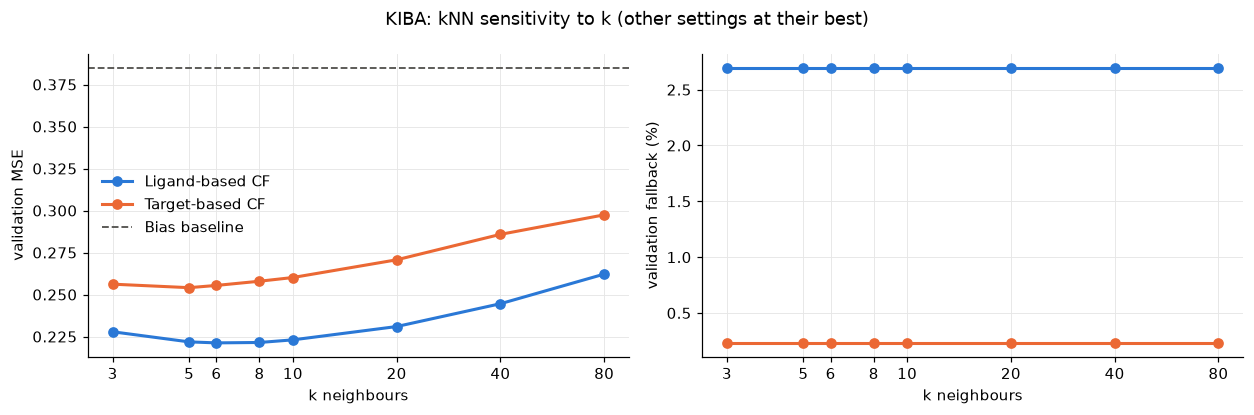

Ligand-based CF {'sim': {'cosine': 0.2198, 'pearson': 0.2197}, 'shrink': {0: 0.221, 10: 0.2197, 25: 0.22, 50: 0.2207, 100: 0.2216}, 'min_common': {2: 0.2197, 5: 0.2223, 10: 0.2425}, 'keep_negative': {False: 0.2197, True: 0.2251}}
Target-based CF {'sim': {'cosine': 0.2573, 'pearson': 0.2541}, 'shrink': {0: 0.2562, 10: 0.2543, 25: 0.2541, 50: 0.255, 100: 0.256}, 'min_common': {2: 0.2543, 5: 0.2548, 10: 0.2541}, 'keep_negative': {False: 0.2541, True: 0.2553}}


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
for variant, label in VARIANTS.items():
    cfg = best_knn[variant]
    g = knn_grid[(knn_grid.variant == variant) & (knn_grid.sim == cfg["sim"]) & (knn_grid.shrink == cfg["shrink"])
                 & (knn_grid.min_common == cfg["min_common"]) & (knn_grid.keep_negative == cfg["keep_negative"])]
    axes[0].plot(g.k, g.val_mse, marker="o", markersize=6, color=COLORS[label], label=label)
    axes[1].plot(g.k, 100 * g.val_fallback, marker="o", markersize=6, color=COLORS[label], label=label)
axes[0].axhline(mse(Y["val"], baseline_preds["Bias baseline"]["val"]), color=COLORS["Bias baseline"],
                linestyle="--", linewidth=1.2, label="Bias baseline")
for ax, ylab in zip(axes, ["validation MSE", "validation fallback (%)"]):
    ax.set_xscale("log", base=2)
    ax.set_xticks(K_GRID)
    ax.set_xticklabels(K_GRID)
    ax.set_xlabel("k neighbours")
    ax.set_ylabel(ylab)
axes[0].legend(frameon=False)
fig.suptitle("KIBA: kNN sensitivity to k (other settings at their best)")
fig.tight_layout()
fig.savefig(FIG_DIR / "task2_cf_k_sensitivity.png", dpi=200, bbox_inches="tight")
plt.show()

for variant, label in VARIANTS.items():
    g = knn_grid[knn_grid.variant == variant]
    print(label, {c: g.groupby(c).val_mse.min().round(4).to_dict() for c in ["sim", "shrink", "min_common", "keep_negative"]})

## 6. Matrix factorisation

Latent factor model with biases:

$$\hat r_{xi} = \mu + b_x + b_i + p_x^\top q_i$$

Fit by **alternating least squares (ALS)** with **weighted-λ** regularisation (Zhou et al., 2008): each ligand or target is penalised by λ times its number of training ratings. On KIBA this matters more than on DAVIS: a ligand with 8 training pairs and one with 116 get proportionate penalties. Training stops early on validation MSE (patience 5 sweeps), and the best sweep is kept.

Grid: rank ∈ {2, 4, 8, 16, 32, 48, 64} × λ ∈ {0.001, 0.01, 0.025, 0.05, 0.1, 0.5, 1.0} = 49 settings (same grid as DAVIS). At rank 48–64 most ligands already have more parameters than training pairs, so λ controls complexity.

In [18]:
def fit_mf(R, val_lig, val_tgt, val_y, rank, lam, max_sweeps=100, patience=5, seed=SEED):
    rng = np.random.default_rng(seed)
    obs = np.isfinite(R)
    mu_ = R[obs].mean()
    P = rng.normal(0, 0.1, (R.shape[0], rank))
    Q = rng.normal(0, 0.1, (R.shape[1], rank))
    bl, bt = np.zeros(R.shape[0]), np.zeros(R.shape[1])
    row_obs = [np.flatnonzero(obs[x]) for x in range(R.shape[0])]
    col_obs = [np.flatnonzero(obs[:, i]) for i in range(R.shape[1])]
    eye = np.eye(rank + 1)

    def half_step(Rm, observed, F_other, b_other):
        F, b = np.zeros((len(observed), rank)), np.zeros(len(observed))
        for x, cols in enumerate(observed):
            if len(cols) == 0:
                continue
            phi = np.hstack([np.ones((len(cols), 1)), F_other[cols]])
            sol = np.linalg.solve(phi.T @ phi + lam * len(cols) * eye, phi.T @ (Rm[x, cols] - mu_ - b_other[cols]))
            b[x], F[x] = sol[0], sol[1:]
        return F, b

    best_v, best, history, wait = np.inf, None, [], 0
    for sweep in range(1, max_sweeps + 1):
        P, bl = half_step(R, row_obs, Q, bt)
        Q, bt = half_step(R.T, col_obs, P, bl)
        v = mse(val_y, mu_ + bl[val_lig] + bt[val_tgt] + (P[val_lig] * Q[val_tgt]).sum(1))
        history.append(v)
        if v < best_v - 1e-6:
            best_v, best, wait = v, (bl.copy(), bt.copy(), P.copy(), Q.copy(), sweep), 0
        else:
            wait += 1
            if wait >= patience:
                break
    bl, bt, P, Q, best_sweep = best
    return {"mu": mu_, "b_ligand": bl, "b_target": bt, "P": P, "Q": Q, "sweeps": best_sweep, "history": history}

In [19]:
RANK_GRID = [2, 4, 8, 16, 32, 48, 64]
LAM_GRID = [0.001, 0.01, 0.025, 0.05, 0.1, 0.5, 1.0]

In [20]:
t0 = time.time()
mf_grid, mf_fits = [], {}
for rank in RANK_GRID:
    for lam in LAM_GRID:
        fit = fit_mf(R_train, *IDX["val"], Y["val"], rank, lam)
        mf_fits[(rank, lam)] = fit
        mf_grid.append({"rank": rank, "lam": lam, "val_mse": min(fit["history"]), "sweeps": fit["sweeps"]})
mf_grid = pd.DataFrame(mf_grid)
print(f"{len(mf_grid)} settings in {time.time() - t0:.1f}s")


def mf_pred(fit, lig, tgt):
    return fit["mu"] + fit["b_ligand"][lig] + fit["b_target"][tgt] + (fit["P"][lig] * fit["Q"][tgt]).sum(1)


g = mf_grid.sort_values("val_mse")
near = g[g.val_mse <= g.val_mse.iloc[0] + 5e-3].copy()
near["val_ci"] = [concordance_index_tau(Y["val"], mf_pred(mf_fits[(r, l)], *IDX["val"])) for r, l in zip(near["rank"], near.lam)]
best = near.sort_values(["val_ci", "val_mse"], ascending=[False, True]).iloc[0]
best_mf = {"rank": int(best["rank"]), "lam": float(best.lam), "sweeps": int(best.sweeps)}
print(f"Matrix factorisation: {best_mf} | val MSE {best.val_mse:.4f} | val CI {best.val_ci:.4f}")
mf_grid.pivot(index="rank", columns="lam", values="val_mse").round(4)

49 settings in 91.9s
Matrix factorisation: {'rank': 64, 'lam': 0.025, 'sweeps': 41} | val MSE 0.1912 | val CI 0.8565


lam,0.001,0.010,0.025,0.050,0.100,0.500,1.000
rank,,,,,,,
2,0.2988,0.2870,0.2745,0.2724,0.2818,0.3962,0.4400
4,0.3036,0.2712,0.2561,0.2513,0.2670,0.3962,0.4401
8,0.3213,0.2604,0.2294,0.2224,0.2528,0.3962,0.4402
16,0.3041,0.2236,0.2014,0.2074,0.2509,0.3962,0.4405
32,0.3184,0.2177,0.1920,0.2038,0.2507,0.3961,0.4410
48,0.3620,0.2065,0.1907,0.2038,0.2507,0.3960,0.4411
64,0.3835,0.1993,0.1912,0.2038,0.2507,0.3960,0.4411


## 7. Final test evaluation (E1)

Each model is fit on train with its chosen setting and evaluated on test once. For kNN the "fit" is the similarity matrix built on train. For MF the train-only fit from tuning is the final model; validation chose only the hyperparameters and the stopping sweep.

Every model is stored in the same dictionary format that is saved in §8, so the in-memory and reloaded models go through the same `predict_pairs`.

In [21]:
LIGAND_IDS = np.arange(n_lig)
TARGET_IDS = np.arange(n_tgt)


def make_knn_model(variant, R, cfg):
    mu_, bl, bt = fit_bias(R)
    S = finalise_similarity(*raw_similarity(variant_matrix(variant, R), cfg["sim"]), cfg["shrink"], cfg["min_common"])
    return {"model_type": variant, "hyperparams": dict(cfg), "mu": mu_, "b_ligand": bl, "b_target": bt,
            "R_train": R, "S": S, "ligand_ids": LIGAND_IDS, "target_ids": TARGET_IDS}


def make_mf_model(fit, cfg):
    return {"model_type": "mf", "hyperparams": dict(cfg), "mu": fit["mu"], "b_ligand": fit["b_ligand"],
            "b_target": fit["b_target"], "P": fit["P"], "Q": fit["Q"],
            "ligand_ids": LIGAND_IDS, "target_ids": TARGET_IDS}


def predict_pairs(model, lig, tgt):
    '''prediction from a model dict only; returns (prediction, used_neighbours)'''
    t, hp = model["model_type"], model["hyperparams"]
    if t == "mf":
        pred = model["mu"] + model["b_ligand"][lig] + model["b_target"][tgt] + (model["P"][lig] * model["Q"][tgt]).sum(1)
        return pred, np.ones(len(lig), bool)
    out = knn_variant(t, model["R_train"], model["S"], model["mu"], model["b_ligand"], model["b_target"],
                      lig, tgt, [hp["k"]], hp["keep_negative"])
    return out[hp["k"]]

In [22]:
cf_models = {VARIANTS[v]: make_knn_model(v, R_train, best_knn[v]) for v in VARIANTS}
cf_models["Matrix factorisation"] = make_mf_model(mf_fits[(best_mf["rank"], best_mf["lam"])], best_mf)

rows = [evaluate(name, pred) for name, pred in baseline_preds.items()] + [random_row]
cf_test_pred, cf_test_used = {}, {}
for name, model in cf_models.items():
    out = {p: predict_pairs(model, *IDX[p]) for p in IDX}
    cf_test_pred[name], cf_test_used[name] = out["test"]
    rows.append(evaluate(name, {p: o[0] for p, o in out.items()},
                         used=None if model["model_type"] == "mf" else out["test"][1]))
e1 = pd.DataFrame(rows).set_index("model")
e1.to_csv(RES_DIR / "task2_e1_results.csv")
e1.round(4)

,MSE train,MSE val,MSE test,RMSE test,CI test,CI per ligand,Hit@1,Hit@5,MRR,NDCG@5,mean rank of best,fallback %,MSE test non-spike,CI test non-spike
model,,,,,,,,,,,,,,
Global mean,0.6913,0.7075,0.7073,0.8410,0.5000,0.5000,0.1957,0.4607,0.3883,0.5709,5.8539,NaN,0.8211,0.5000
Ligand mean,0.3992,0.4384,0.4325,0.6576,0.7036,0.5000,0.1957,0.4607,0.3883,0.5709,5.8539,NaN,0.4825,0.7014
Target mean,0.5932,0.6155,0.6072,0.7792,0.6871,0.6721,0.3298,0.6720,0.5215,0.7439,3.9712,NaN,0.7379,0.6329
Bias baseline,0.3466,0.3850,0.3765,0.6136,0.7806,0.6721,0.3298,0.6720,0.5215,0.7439,3.9712,NaN,0.4439,0.7472
Random ranking,NaN,NaN,NaN,NaN,NaN,0.4994,0.1868,0.4717,0.3851,0.5705,5.8370,NaN,NaN,NaN
Ligand-based CF,0.1246,0.2215,0.2246,0.4739,0.8473,0.7981,0.5697,0.8813,0.7210,0.8742,2.3794,2.3854,0.2678,0.8252
Target-based CF,0.2266,0.2541,0.2515,0.5015,0.8269,0.7345,0.4618,0.8374,0.6418,0.8365,2.7929,0.2096,0.2973,0.8042
Matrix factorisation,0.0349,0.1912,0.2007,0.4479,0.8562,0.7920,0.5523,0.8916,0.7129,0.8801,2.2862,NaN,0.2400,0.8337


**Chosen settings** (fit on train, chosen on validation MSE with validation CI as the tie-breaker):

In [23]:
hp_table = pd.DataFrame([
    {"model": "Ligand-based CF", **best_knn["user_knn"]},
    {"model": "Target-based CF", **best_knn["item_knn"]},
    {"model": "Matrix factorisation", **best_mf},
]).set_index("model")
hp_table["val MSE"] = [e1.loc[m, "MSE val"] for m in hp_table.index]
hp_table.to_csv(RES_DIR / "task2_hyperparams.csv")
hp_table

,sim,shrink,min_common,keep_negative,k,rank,lam,sweeps,val MSE
model,,,,,,,,,
Ligand-based CF,pearson,50.0,2.0,False,8.0,NaN,NaN,NaN,0.2215
Target-based CF,pearson,25.0,10.0,False,5.0,NaN,NaN,NaN,0.2541
Matrix factorisation,NaN,NaN,NaN,NaN,NaN,64.0,0.025,41.0,0.1912


## 8. Save the best CF model and check that it reloads

The best CF model is the one with the lowest **validation** MSE, so test plays no part in model selection. It is saved as `saved_models/kiba_cf.npz`; the other two CF models are saved under their own names. Each file holds everything `predict` needs:
- `model_type` and the hyperparameters (as JSON)
- `ligand_ids` / `target_ids` (matrix indices) and `ligand_labels` / `target_labels` (CHEMBL / UniProt)
- `mu`, `b_ligand`, `b_target`
- `R_train` + `S` (kNN), or `P` + `Q` (MF)
- `score_scale`, `seed` and the split file name

Files are written with `np.savez_compressed` (the ligand–ligand similarity matrix is 2,068 × 2,068) and loaded with `allow_pickle=False`.

In [24]:
def save_model(path, model):
    arrays = {k: v for k, v in model.items() if k != "hyperparams"}
    arrays.update(hyperparams=json.dumps(model["hyperparams"]), ligand_labels=LIG_LABELS, target_labels=TGT_LABELS,
                  score_scale=SCORE_SCALE, seed=SEED, split_file=SPLIT_PATH.name)
    np.savez_compressed(path, **{k: np.asarray(v) for k, v in arrays.items()})


def load_model(path):
    with np.load(path, allow_pickle=False) as z:
        model = {k: z[k] for k in z.files}
    for k in ["model_type", "hyperparams", "score_scale", "split_file"]:
        model[k] = str(model[k])
    model["hyperparams"] = json.loads(model["hyperparams"])
    model["seed"] = int(model["seed"])
    model["mu"] = float(model["mu"])
    return model


def predict(model, ligand_id, target_ids):
    '''scores for one ligand against a list of targets, using only the loaded dict'''
    lig_pos = {v: i for i, v in enumerate(model["ligand_ids"])}
    tgt_pos = {v: i for i, v in enumerate(model["target_ids"])}
    tgt = np.array([tgt_pos[t] for t in target_ids])
    lig = np.full(len(tgt), lig_pos[ligand_id])
    return predict_pairs(model, lig, tgt)


cf_names = list(cf_models)
best_cf = min(cf_names, key=lambda m: e1.loc[m, "MSE val"])
print("best CF model on validation MSE:", best_cf)
file_names = {"Ligand-based CF": "kiba_user_knn.npz", "Target-based CF": "kiba_item_knn.npz",
              "Matrix factorisation": "kiba_mf.npz"}
for name, model in cf_models.items():
    save_model(MODEL_DIR / file_names[name], model)
save_model(MODEL_DIR / f"{DATASET}_cf.npz", cf_models[best_cf])
print("saved:", {p.name: f"{p.stat().st_size / 1e6:.1f} MB" for p in sorted(MODEL_DIR.glob(f"{DATASET}_*.npz"))})

best CF model on validation MSE: Matrix factorisation


saved: {'kiba_cf.npz': '1.2 MB', 'kiba_item_knn.npz': '0.4 MB', 'kiba_mf.npz': '1.2 MB', 'kiba_user_knn.npz': '16.9 MB'}


In [25]:
# reload check: in-memory prediction == prediction from the file, and test MSE matches the E1 table
test = parts["test"]
pred_before = np.empty(len(test))
pred_after = np.empty(len(test))
reloaded = load_model(MODEL_DIR / f"{DATASET}_cf.npz")
for l, idx in test.groupby("lig_id").groups.items():
    pred_before[idx] = predict(cf_models[best_cf], l, test.loc[idx, "tgt_id"].values)[0]
    pred_after[idx] = predict(reloaded, l, test.loc[idx, "tgt_id"].values)[0]
assert np.allclose(pred_before, pred_after)
print(f"reloaded {reloaded['model_type']} {reloaded['hyperparams']} | {reloaded['score_scale']}")
print(f"test MSE from reloaded model: {mse(Y['test'], pred_after):.4f} | E1 table: {e1.loc[best_cf, 'MSE test']:.4f}")

reloaded mf {'rank': 64, 'lam': 0.025, 'sweeps': 41} | KIBA score (DeepDTA transformed scale), higher = stronger
test MSE from reloaded model: 0.2007 | E1 table: 0.2007


## 9. Analyses

### E2: ligand-based vs target-based CF by target community and target degree

**H1** (as on DAVIS): target-based CF beats ligand-based CF. Task 1 found that sequence-similar KIBA targets have clearly correlated binding profiles (median r 0.54 for the top 5% most similar target pairs), while ligand structure matters much less (0.30).

**Counter-argument for KIBA:** ligand–ligand similarities rest on few co-rated targets, but target–target similarities rest on many co-rated ligands, which should favour target-based CF even more than on DAVIS.

**H2:** every CF model beats the bias baseline on test.

Louvain is run on the **training pairs only**: a bipartite graph of strong training pairs (score ≥ 12.1), weighted by score. Communities with fewer than 10 targets, and targets with no strong training ligand, are grouped as "other". **Target degree** is the number of strong training ligands of a target.

Louvain on strong training pairs: 7 communities, modularity 0.339, 7 with >= 10 targets, 3 targets with no strong training ligand

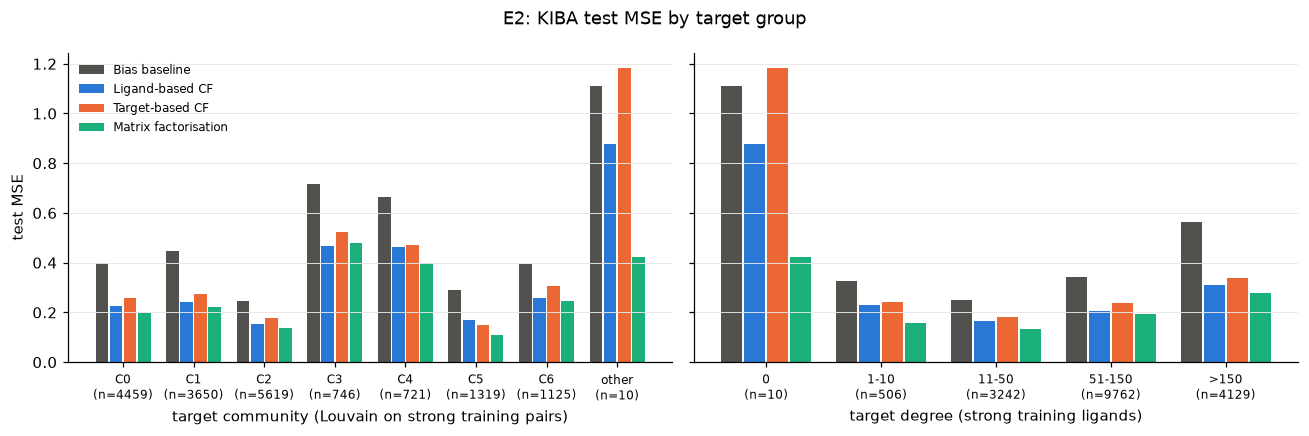

,Bias baseline,Ligand-based CF,Target-based CF,Matrix factorisation,pairs,share >= 12.1
C0,0.3968,0.2254,0.2595,0.1983,4459.0,0.2409
C1,0.4489,0.2432,0.2735,0.2215,3650.0,0.2493
C2,0.2469,0.1540,0.1777,0.1379,5619.0,0.1520
C3,0.7161,0.4665,0.5228,0.4795,746.0,0.4062
C4,0.6649,0.4639,0.4716,0.4007,721.0,0.2871
C5,0.2906,0.1713,0.1496,0.1095,1319.0,0.1721
C6,0.3933,0.2571,0.3065,0.2477,1125.0,0.1404
other,1.1107,0.8769,1.1845,0.4220,10.0,0.2000


,Bias baseline,Ligand-based CF,Target-based CF,Matrix factorisation,pairs,share >= 12.1
0,1.1107,0.8769,1.1845,0.4220,10.0,0.2000
1-10,0.3263,0.2291,0.2432,0.1579,506.0,0.0889
11-50,0.2505,0.1667,0.1825,0.1328,3242.0,0.1006
51-150,0.3411,0.2075,0.2377,0.1918,9762.0,0.2005
>150,0.5637,0.3083,0.3370,0.2796,4129.0,0.3403


In [26]:
strong_train = parts["train"][parts["train"].score >= STRONG]
G = nx.Graph()
G.add_weighted_edges_from(zip(zip(["lig"] * len(strong_train), strong_train.lig),
                              zip(["tgt"] * len(strong_train), strong_train.tgt), strong_train.score))
comms = sorted(nx.community.louvain_communities(G, weight="weight", seed=1), key=len, reverse=True)
tgt_comm = {n: ci for ci, c in enumerate(comms) for k, n in c if k == "tgt"}
comm_size = pd.Series(tgt_comm).value_counts()
big = set(comm_size[comm_size >= 10].index)
print(f"Louvain on strong training pairs: {len(comms)} communities, modularity "
      f"{nx.community.modularity(G, comms, weight='weight'):.3f}, {len(big)} with >= 10 targets, "
      f"{n_tgt - len(tgt_comm)} targets with no strong training ligand")

ev = parts["test"][["lig", "tgt", "lig_id", "tgt_id", "score"]].copy()
ev["community"] = [f"C{tgt_comm[t]}" if tgt_comm.get(t) in big else "other" for t in ev.tgt]
deg = strong_train.groupby("tgt_id").size().reindex(range(n_tgt), fill_value=0)
ev["degree"] = pd.cut(deg[ev.tgt_id].values, [-1, 0, 10, 50, 150, 10_000], labels=["0", "1-10", "11-50", "51-150", ">150"])
ev["Bias baseline"] = baseline_preds["Bias baseline"]["test"]
ALL_MODELS = ["Bias baseline", "Ligand-based CF", "Target-based CF", "Matrix factorisation"]
for name in ALL_MODELS[1:]:
    ev[name] = cf_test_pred[name]


def group_mse(df, by, models=ALL_MODELS):
    return pd.DataFrame({key: {**{m: mse(g.score, g[m]) for m in models}, "pairs": len(g),
                               "share >= 12.1": (g.score >= STRONG).mean()}
                         for key, g in df.groupby(by, observed=True)}).T


e2_comm = group_mse(ev, "community")
e2_comm = e2_comm.loc[sorted(e2_comm.index, key=lambda c: (c == "other", int(c[1:]) if c != "other" else 0))]
e2_deg = group_mse(ev, "degree")


def group_bars(tables, xlabels, title, path):
    fig, axes = plt.subplots(1, len(tables), figsize=(6 * len(tables), 4), sharey=True)
    axes = np.atleast_1d(axes)
    w = 0.2
    for ax, tab, xlabel in zip(axes, tables, xlabels):
        x = np.arange(len(tab))
        for j, m in enumerate(ALL_MODELS):
            ax.bar(x + (j - 1.5) * w, tab[m], width=w - 0.02, color=COLORS[m], label=m)
        ax.set_xticks(x)
        ax.set_xticklabels([f"{i}\n(n={int(n)})" for i, n in zip(tab.index, tab.pairs)], fontsize=8)
        ax.set_xlabel(xlabel)
        ax.grid(axis="x", visible=False)
    axes[0].set_ylabel("test MSE")
    axes[0].legend(frameon=False, fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()


group_bars([e2_comm, e2_deg], ["target community (Louvain on strong training pairs)",
                               "target degree (strong training ligands)"],
           "E2: KIBA test MSE by target group", FIG_DIR / "task2_e2_groups.png")
e2_comm.to_csv(RES_DIR / "task2_e2_communities.csv")
e2_deg.to_csv(RES_DIR / "task2_e2_degree.csv")
display(e2_comm.round(4), e2_deg.round(4))

### E3: effect of sparsity per ligand, and neighbour availability

This is the KIBA question DAVIS could not ask (every DAVIS ligand had about 309 training pairs). Test pairs are binned by how many training pairs their **ligand** has. For each bin we report test MSE for every model, the kNN fallback rate, and the number of **usable neighbours**, i.e. candidates with a non-zero similarity that the ligand (target-based) or target (ligand-based) has a training score for, before the top-k cut.

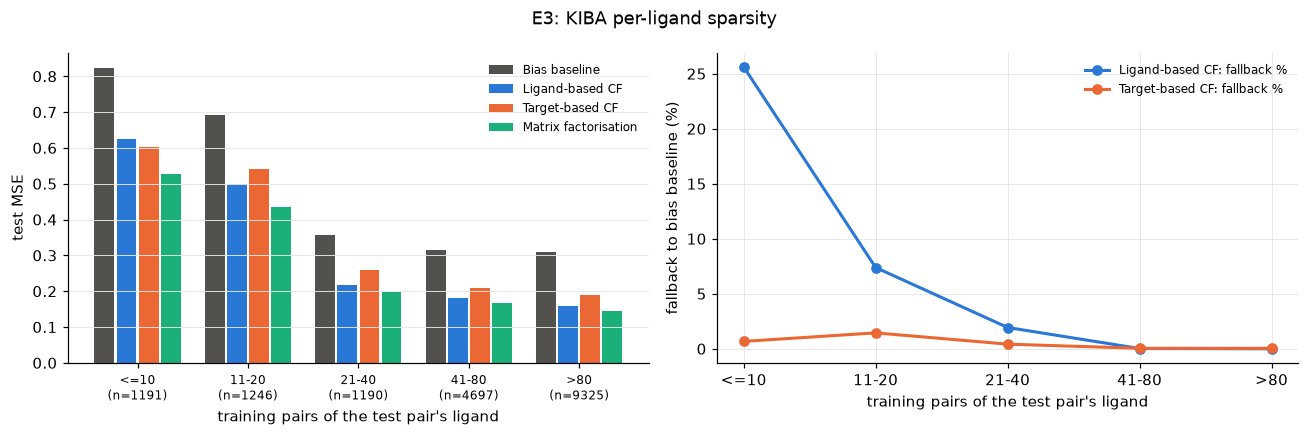

,Bias baseline,Ligand-based CF,Target-based CF,Matrix factorisation,pairs,share >= 12.1,fallback % Ligand-based CF,median usable nbrs Ligand-based CF,fallback % Target-based CF,median usable nbrs Target-based CF
<=10,0.824,0.625,0.601,0.527,1191.0,0.348,25.609,76.0,0.672,7.0
11-20,0.691,0.499,0.541,0.434,1246.0,0.268,7.384,182.0,1.445,13.0
21-40,0.358,0.218,0.258,0.196,1190.0,0.171,1.933,315.0,0.420,30.0
41-80,0.316,0.181,0.209,0.166,4697.0,0.186,0.021,400.0,0.043,50.0
>80,0.311,0.160,0.188,0.146,9325.0,0.205,0.000,431.0,0.043,85.0


In [27]:
def usable_neighbours(model, lig, tgt, block=1500):
    '''for each pair, how many columns could act as neighbours (observed and non-zero / positive similarity)'''
    t, hp = model["model_type"], model["hyperparams"]
    R, S = model["R_train"], model["S"]
    rows, cols = (lig, tgt) if t == "item_knn" else (tgt, lig)
    Rv = R if t == "item_knn" else R.T
    obs = np.isfinite(Rv)
    out = np.empty(len(rows), int)
    for s in range(0, len(rows), block):
        W = S[cols[s:s + block]]
        ok = (W != 0) if hp["keep_negative"] else (W > 0)
        out[s:s + block] = (obs[rows[s:s + block]] & ok).sum(1)
    return out


train_per_lig = np.isfinite(R_train).sum(1)
ev["ligand train pairs"] = pd.cut(train_per_lig[ev.lig_id.values], [0, 10, 20, 40, 80, 1000],
                                  labels=["<=10", "11-20", "21-40", "41-80", ">80"])
for name in ["Ligand-based CF", "Target-based CF"]:
    ev[f"used {name}"] = cf_test_used[name]
    ev[f"nbrs {name}"] = usable_neighbours(cf_models[name], *IDX["test"])

e3 = group_mse(ev, "ligand train pairs")
for name in ["Ligand-based CF", "Target-based CF"]:
    grp = ev.groupby("ligand train pairs", observed=True)
    e3[f"fallback % {name}"] = 100 * (1 - grp[f"used {name}"].mean())
    e3[f"median usable nbrs {name}"] = grp[f"nbrs {name}"].median()
e3.to_csv(RES_DIR / "task2_e3_sparsity.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(len(e3))
w = 0.2
for j, m in enumerate(ALL_MODELS):
    axes[0].bar(x + (j - 1.5) * w, e3[m], width=w - 0.02, color=COLORS[m], label=m)
axes[0].set_xticks(x)
axes[0].set_xticklabels([f"{i}\n(n={int(n)})" for i, n in zip(e3.index, e3.pairs)], fontsize=8)
axes[0].set_xlabel("training pairs of the test pair's ligand")
axes[0].set_ylabel("test MSE")
axes[0].legend(frameon=False, fontsize=8)
axes[0].grid(axis="x", visible=False)
for name in ["Ligand-based CF", "Target-based CF"]:
    axes[1].plot(x, e3[f"fallback % {name}"], marker="o", color=COLORS[name], label=f"{name}: fallback %")
axes[1].set_xticks(x)
axes[1].set_xticklabels(e3.index)
axes[1].set_xlabel("training pairs of the test pair's ligand")
axes[1].set_ylabel("fallback to bias baseline (%)")
axes[1].legend(frameon=False, fontsize=8)
fig.suptitle("E3: KIBA per-ligand sparsity")
fig.tight_layout()
fig.savefig(FIG_DIR / "task2_e3_sparsity.png", dpi=200, bbox_inches="tight")
plt.show()
e3.round(3)

### E4: heaped (spike) values and abnormal records

The KIBA counterpart of the DAVIS floor analysis. Test pairs are split into: spike pairs (true score exactly 11.1 / 11.2), other ordinary pairs, strong binders (≥ 12.1, overlapping "other"), and abnormal records (Task 1 flags: far-low scores and the abnormal ligand CHEMBL373751). A **constant 11.15** predictor is added as a reference for how much MSE can be won on spike pairs by predicting the heap alone.

In [28]:
tp = parts["test"]
groups = {"all": np.ones(len(tp), bool), "spike (11.1/11.2)": tp.flag_spike.values,
          "non-spike": ~tp.flag_spike.values, "strong (>= 12.1)": tp.score.values >= STRONG,
          "far-low or abnormal ligand": (tp.flag_far_low | tp.flag_low_ligand).values}
e4_preds = {**{m: baseline_preds[m]["test"] for m in ["Ligand mean", "Bias baseline"]},
            **cf_test_pred, "Constant 11.15": np.full(len(tp), np.mean(SPIKES))}
e4 = pd.DataFrame({name: {f"MSE {g}": mse(Y["test"][m], p[m]) if m.any() else np.nan for g, m in groups.items()}
                   | {"CI non-spike": concordance_index_tau(Y["test"][nonspike], p[nonspike])}
                   for name, p in e4_preds.items()}).T
print("test pairs per group:", {g: int(m.sum()) for g, m in groups.items()})
n_all, n_spk = len(tp), int(tp.flag_spike.sum())
print(f"spike-vs-spike sample pairs among all test sample pairs: {n_spk * (n_spk - 1) / (n_all * (n_all - 1)):.1%} "
      "(half of them are tied 11.1-11.1 or 11.2-11.2 and excluded from CI)")
e4.to_csv(RES_DIR / "task2_e4_spikes_abnormal.csv")
e4.round(4)

test pairs per group: {'all': 17649, 'spike (11.1/11.2)': 4038, 'non-spike': 13611, 'strong (>= 12.1)': 3735, 'far-low or abnormal ligand': 8}
spike-vs-spike sample pairs among all test sample pairs: 5.2% (half of them are tied 11.1-11.1 or 11.2-11.2 and excluded from CI)


,MSE all,MSE spike (11.1/11.2),MSE non-spike,MSE strong (>= 12.1),MSE far-low or abnormal ligand,CI non-spike
Ligand mean,0.4325,0.2640,0.4825,1.2892,13.9401,0.7014
Bias baseline,0.3765,0.1496,0.4439,1.0972,14.2859,0.7472
Ligand-based CF,0.2246,0.0789,0.2678,0.6067,13.4543,0.8252
Target-based CF,0.2515,0.0968,0.2973,0.6625,13.2995,0.8042
Matrix factorisation,0.2007,0.0679,0.2400,0.5762,19.2689,0.8337
Constant 11.15,1.0338,0.0025,1.3398,3.9094,44.4781,0.5000


**The abnormal ligand.** How does each model treat CHEMBL373751? Its training mean is far below every other ligand's, so the ligand bias b_x already absorbs most of its offset. The question is what the neighbour and factor terms add on top.

In [29]:
ab = tp[tp.lig == ABNORMAL_LIGAND]
ab_lid = int(np.flatnonzero(LIG_LABELS == ABNORMAL_LIGAND)[0])
print(f"{ABNORMAL_LIGAND}: train pairs {int(train_per_lig[ab_lid])}, training mean {np.nanmean(R_train[ab_lid]):.2f}, "
      f"ligand bias b_x {b_lig[ab_lid]:+.2f} | test pairs {len(ab)}")
if len(ab):
    show = ab[["tgt", "score"]].copy()
    m_ = (tp.lig == ABNORMAL_LIGAND).values
    show["Bias baseline"] = baseline_preds["Bias baseline"]["test"][m_]
    for name in cf_test_pred:
        show[name] = cf_test_pred[name][m_]
    display(show.round(3))

# its neighbours in ligand-based CF: who is "similar" to it, and on how many co-rated targets?
S_u = cf_models["Ligand-based CF"]["S"]
n_co_u = raw_similarity(R_train.T, cf_models["Ligand-based CF"]["hyperparams"]["sim"])[1]
nb = np.argsort(-np.abs(S_u[ab_lid]))[:5]
pd.DataFrame({"neighbour": LIG_LABELS[nb], "similarity": S_u[ab_lid, nb], "co-rated targets": n_co_u[ab_lid, nb],
              "neighbour training mean": np.nanmean(R_train[nb], 1)}).round(3)

CHEMBL373751: train pairs 5, training mean 2.96, ligand bias b_x -8.76 | test pairs 5


,tgt,score,Bias baseline,Ligand-based CF,Target-based CF,Matrix factorisation
15407,O14920,6.1,2.805,2.927,6.104,6.137
15408,P00533,1.1,3.003,3.032,3.895,7.045
15409,P04626,1.1,3.172,3.167,3.810,6.494
15410,P53779,1.3,3.004,4.096,3.359,5.342
15411,Q16539,10.9,2.927,3.689,2.763,4.410


,neighbour,similarity,co-rated targets,neighbour training mean
0,CHEMBL398951,0.072,4.0,11.556
1,CHEMBL2004438,0.072,4.0,11.703
2,CHEMBL1984842,0.072,4.0,11.599
3,CHEMBL1990885,0.069,4.0,12.151
4,CHEMBL565612,-0.057,3.0,11.886


### Extra: MF target factors

The MF target factors q_i are projected to 2D with PCA and coloured by the train-only Louvain communities from E2. If targets from one community sit together, MF has learned the same target groups.

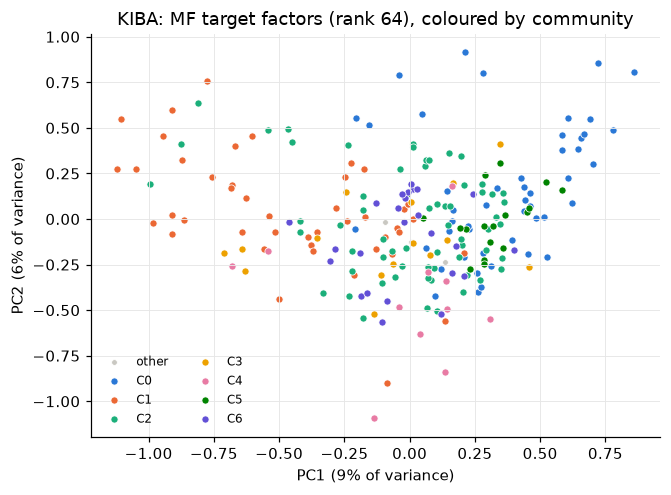

mean factor distance, same community: 1.763 | different community: 1.853


In [30]:
Q = cf_models["Matrix factorisation"]["Q"]
Qc = Q - Q.mean(0)
U, sv, Vt = np.linalg.svd(Qc, full_matrices=False)
Z = Qc @ Vt[:2].T
labels = np.array([f"C{tgt_comm[t]}" if tgt_comm.get(t) in big else "other" for t in TGT_LABELS])
palette = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
fig, ax = plt.subplots(figsize=(6.2, 4.6))
ax.scatter(*Z[labels == "other"].T, s=14, color="#c9c8c2", label="other", edgecolor="white", linewidth=0.5)
for j, c in enumerate(sorted(set(labels) - {"other"}, key=lambda c: int(c[1:]))[:len(palette)]):
    ax.scatter(*Z[labels == c].T, s=22, color=palette[j], label=c, edgecolor="white", linewidth=0.5)
ax.set_xlabel(f"PC1 ({sv[0] ** 2 / (sv ** 2).sum():.0%} of variance)")
ax.set_ylabel(f"PC2 ({sv[1] ** 2 / (sv ** 2).sum():.0%} of variance)")
ax.set_title(f"KIBA: MF target factors (rank {best_mf['rank']}), coloured by community")
ax.legend(frameon=False, fontsize=8, ncol=2)
fig.tight_layout()
fig.savefig(FIG_DIR / "task2_mf_factors.png", dpi=200, bbox_inches="tight")
plt.show()

in_big = labels != "other"
D = np.linalg.norm(Q[in_big][:, None] - Q[in_big][None], axis=2)
same = labels[in_big][:, None] == labels[in_big][None]
np.fill_diagonal(same, False)
print(f"mean factor distance, same community: {D[same].mean():.3f} | "
      f"different community: {D[~same & ~np.eye(len(D), dtype=bool)].mean():.3f}")

## 10. Case study

Every prediction in this section comes from `saved_models/kiba_cf.npz`, loaded from disk. The bias baseline is shown for contrast.

**Choosing the ligands.** The brief suggests CHEMBL1967538, CHEMBL2004544 and CHEMBL565612. None of them was merged in Task 1 (each is its own representative), so they are looked up directly. The cell below shows how much data each has and how many test candidates it gets.

In [31]:
lig_of = dict(zip(LIG_LABELS, range(n_lig)))
CASE_LIGANDS = {c: lig_of[c] for c in ["CHEMBL1967538", "CHEMBL2004544", "CHEMBL565612"]}
model = load_model(MODEL_DIR / f"{DATASET}_cf.npz")
print(f"loaded {model['model_type']} {model['hyperparams']} | {model['score_scale']} | split {model['split_file']}")

slot = []
for cid, l in CASE_LIGANDS.items():
    lt, lr = parts["test"][parts["test"].lig_id == l], parts["train"][parts["train"].lig_id == l]
    slot.append({"ligand": cid, "lig_id": l, "train pairs": len(lr), "test targets": len(lt),
                 "test share spike": lt.flag_spike.mean() if len(lt) else np.nan,
                 "test >= 12.1": int((lt.score >= STRONG).sum()), "max test score": lt.score.max(),
                 "train mean": lr.score.mean(), "train >= 12.1": int((lr.score >= STRONG).sum())})
slot = pd.DataFrame(slot).set_index("ligand")
assert (slot["test targets"] >= 2).all(), "every case ligand needs at least two test targets to be ranked"
slot.round(3)

loaded mf {'rank': 64, 'lam': 0.025, 'sweeps': 41} | KIBA score (DeepDTA transformed scale), higher = stronger | split kiba_split.csv


,lig_id,train pairs,test targets,test share spike,test >= 12.1,max test score,train mean,train >= 12.1
ligand,,,,,,,,
CHEMBL1967538,884,25,3,0.000,0,10.700,10.428,0
CHEMBL2004544,537,65,23,0.304,5,12.600,11.492,8
CHEMBL565612,640,123,23,0.217,4,14.986,11.886,28


In [32]:
def case_table(l, top=10):
    lt = parts["test"][parts["test"].lig_id == l].reset_index(drop=True)
    y, tg = lt.score.values, lt.tgt_id.values
    cf, used = predict(model, l, tg)
    bias = mu + b_lig[l] + b_tgt[tg]
    out = {}
    for name, p in [("CF", cf), ("Bias baseline", bias)]:
        rk = ranking_metrics(np.full(len(y), l), y, p)
        order = np.lexsort((np.random.default_rng(SEED).random(len(y)), -p))
        tab = pd.DataFrame({"rank": np.arange(1, len(y) + 1), "target": lt.tgt.values[order],
                            "predicted": p[order], "true score": y[order],
                            "label": np.where(y[order] == y.max(), "correct", "wrong") if np.ptp(y) > 0
                                     else "tie (all equal)"})
        if name == "CF" and model["model_type"] != "mf":
            tab["source"] = np.where(used[order], "neighbours", "fallback b_xi")
        r = rk.iloc[0] if len(rk) else None
        out[name] = (tab.head(top), {"ligand MSE": mse(y, p), "ligand CI": concordance_index_tau(y, p),
                                     "rank of true best": int(r.best_rank) if r is not None else None,
                                     "Hit@1": bool(r.hit1) if r is not None else None,
                                     "Hit@5": bool(r.hit5) if r is not None and r.hit5 == r.hit5 else None,
                                     "NDCG@5": float(r.ndcg5) if r is not None else None,
                                     "candidates": len(y)})
    return out


case_rows = []
for cid, l in CASE_LIGANDS.items():
    res = case_table(l)
    print(f"\n=== {cid}  (lig_id {l}) ===")
    for name, (tab, summary) in res.items():
        case_rows.append({"ligand": cid, "model": name, **summary})
        print(f"-- {name}: " + ", ".join(f"{k} = {v:.3f}" if isinstance(v, float) else f"{k} = {v}" for k, v in summary.items()))
        display(tab.round(3))
pd.DataFrame(case_rows).to_csv(RES_DIR / "task2_case_study.csv", index=False)


=== CHEMBL1967538  (lig_id 884) ===
-- CF: ligand MSE = 0.049, ligand CI = 1.000, rank of true best = 1, Hit@1 = True, Hit@5 = None, NDCG@5 = nan, candidates = 3


,rank,target,predicted,true score,label
0,1,Q13627,10.989,10.7,correct
1,2,P50750,10.530,10.3,wrong
2,3,P35968,10.299,10.2,wrong


-- Bias baseline: ligand MSE = 0.148, ligand CI = 0.667, rank of true best = 2, Hit@1 = False, Hit@5 = None, NDCG@5 = nan, candidates = 3


,rank,target,predicted,true score,label
0,1,P50750,10.832,10.3,wrong
1,2,Q13627,10.649,10.7,correct
2,3,P35968,10.596,10.2,wrong



=== CHEMBL2004544  (lig_id 537) ===
-- CF: ligand MSE = 0.038, ligand CI = 0.918, rank of true best = 1, Hit@1 = True, Hit@5 = True, NDCG@5 = 0.956, candidates = 23


,rank,target,predicted,true score,label
0,1,O00311,12.273,12.6,correct
1,2,Q8IW41,12.191,12.5,wrong
2,3,O95819,12.059,11.8,wrong
3,4,P53350,11.944,12.1,wrong
4,5,P42679,11.875,12.1,wrong
5,6,Q9HAZ1,11.742,12.1,wrong
6,7,Q9H2X6,11.705,11.6,wrong
7,8,Q13557,11.658,11.9,wrong
8,9,P08581,11.576,11.6,wrong
9,10,P45983,11.572,11.6,wrong


... (2 outputs left out)


=== CHEMBL565612  (lig_id 640) ===
-- CF: ligand MSE = 0.313, ligand CI = 0.721, rank of true best = 1, Hit@1 = True, Hit@5 = True, NDCG@5 = 0.993, candidates = 23


,rank,target,predicted,true score,label
0,1,Q05655,13.304,14.986,correct
1,2,Q86V86,12.487,12.600,wrong
2,3,Q9Y4K4,12.333,12.900,wrong
3,4,Q16513,12.314,12.700,wrong
4,5,Q5S007,12.312,12.000,wrong
5,6,P42338,12.221,11.100,wrong
6,7,P54760,12.137,11.100,wrong
7,8,P51817,11.973,11.700,wrong
8,9,Q8IW41,11.944,11.900,wrong
9,10,O00444,11.894,11.500,wrong


-- Bias baseline: ligand MSE = 0.806, ligand CI = 0.608, rank of true best = 20, Hit@1 = False, Hit@5 = False, NDCG@5 = 0.265, candidates = 23


,rank,target,predicted,true score,label
0,1,P36888,12.462,11.900,wrong
1,2,P42685,12.372,11.700,wrong
2,3,P51817,12.263,11.700,wrong
3,4,Q5S007,12.259,12.000,wrong
4,5,O00444,12.126,11.500,wrong
5,6,Q9Y4K4,12.100,12.900,wrong
6,7,Q8IW41,12.091,11.900,wrong
7,8,P08069,12.047,11.499,wrong
8,9,Q05397,12.003,11.325,wrong
9,10,Q16620,11.862,11.500,wrong


**Why these three cases were chosen.** The three ligands suggested in the brief span KIBA's coverage and activity range without needing any manual cherry-picking:
- **CHEMBL1967538 (sparse, weak-binding case):** 25 training pairs (mean 10.43, no strong binder) and only 3 held-out test candidates (`Q13627` at 10.7, `P50750` at 10.3, `P35968` at 10.2), all below the 11.2 spike level. Because it has fewer than 5 candidates and no candidate above 11.2, `Hit@5` and `NDCG@5` are N/A; only `Hit@1`, `CI` and `MSE` apply. The bias baseline puts `P50750` 1st because `P50750` has a higher global target bias, leaving the true best `Q13627` 2nd (`Hit@1 = False`, ligand CI 0.667, MSE 0.148). CF reverses the top two and ranks `Q13627` 1st (`Hit@1 = True`, ligand CI 1.000, MSE 0.049).
- **CHEMBL2004544 (typical, moderate-coverage selective case):** 65 training pairs (8 with score ≥ 12.1) and 23 test candidates (5 strong binders, 30.4% spike). Both CF and the bias baseline rank the true best `O00311` (score 12.6) 1st, so both get `Hit@1 = True`. The difference is in the rest of the top 5: the bias baseline fills ranks 3–5 with globally popular targets that this ligand barely binds (`P35916` at 11.3, `Q9H2X6` at 11.6, `Q9Y4K4` at 11.5) and pushes the second-best true target `Q8IW41` (12.5) down to 6th (`NDCG@5 = 0.677`, ligand CI 0.700, MSE 0.145). CF ranks `Q8IW41` 2nd and places four of the five strong binders (`O00311`, `Q8IW41`, `P53350`, `P42679`) inside the top 5 (`NDCG@5 = 0.956`, ligand CI 0.918, MSE 0.038).
- **CHEMBL565612 (dense, potent inhibitor with an extreme-high target):** 123 training pairs (28 strong) and 23 test candidates, led by `Q05655` (PKC-δ) at 14.986 (a `flag_far_high` record from Task 1), alongside `Q9Y4K4` (12.9), `Q16513` (12.7) and `Q86V86` (12.6). Because `Q05655` is not bound strongly by the average KIBA ligand, its target bias $b_i$ is modest and the bias baseline ranks the true best **20th out of 23** (`Hit@1 = False`, `Hit@5 = False`, `NDCG@5 = 0.265`, ligand CI 0.608, MSE 0.806). Loaded MF ranks `Q05655` **1st** (predicted 13.304) and puts the other three strong binders `Q86V86`, `Q9Y4K4` and `Q16513` at ranks 2–4 (`Hit@1 = True`, `Hit@5 = True`, `NDCG@5 = 0.993`, ligand CI 0.721, MSE 0.313). The interaction term $p_x^\top q_i$ captures kinase-family selectivity that $\mu + b_x + b_i$ cannot express.

## 11. Discussion

The numbers below come from this run on `kiba_split.csv` (2,068 deduplicated ligands × 229 kinase targets, 117,657 observed pairs, 75.16% missing). Every step is seeded (`SEED = 42`), so re-running reproduces the same values.

**Why CF is not a lookup of known answers (E1).** Test pairs are held out from `R_train`, so a table lookup returns `NaN` for all 17,649 test pairs. Every CF model beats the additive bias baseline $\mu + b_x + b_i$ on test MSE, CI, Hit@1, Hit@5, MRR and NDCG@5 (**H2 supported**):

| model | test MSE | CI | CI / ligand | Hit@1 | Hit@5 | MRR | NDCG@5 | mean rank of best |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Random ranking | – | – | 0.499 | 0.187 | 0.472 | 0.385 | 0.571 | 5.84 |
| Ligand mean ($\mu + b_x$) | 0.433 | 0.704 | 0.500 | 0.196 | 0.461 | 0.388 | 0.571 | 5.85 |
| Target mean ($\mu + b_i$) | 0.607 | 0.687 | 0.672 | 0.330 | 0.672 | 0.522 | 0.744 | 3.97 |
| Bias baseline ($\mu + b_x + b_i$) | 0.377 | 0.781 | 0.672 | 0.330 | 0.672 | 0.522 | 0.744 | 3.97 |
| Target-based CF (`item_knn`, $k=5$) | 0.251 | 0.827 | 0.734 | 0.462 | 0.837 | 0.642 | 0.836 | 2.79 |
| Ligand-based CF (`user_knn`, $k=8$) | 0.225 | 0.847 | 0.798 | 0.570 | 0.881 | 0.721 | 0.874 | 2.38 |
| Matrix factorisation (`rank=64, λ=0.025`) | **0.201** | **0.856** | 0.792 | 0.552 | **0.892** | 0.713 | **0.880** | **2.29** |

Two baseline details are worth noting:
- **Ligand mean vs Target mean:** $\mu + b_x$ beats $\mu + b_i$ on global MSE (0.433 vs 0.607) because ligand identity explains 41.7% of KIBA's variance vs 14.1% for target identity (Task 1). Yet for ranking a given ligand's candidate targets, $b_x$ is a constant offset across all candidates, so Ligand mean ties every candidate and scores like Random ranking (CI / ligand 0.500, Hit@1 0.196).
- **Why random Hit@1 and Hit@5 are higher than on DAVIS:** because 75.2% of the KIBA matrix is unmeasured, a test ligand has a median of only **10** measured test candidates (vs **65** on complete DAVIS). Random ordering therefore gets Hit@1 = 0.187 and Hit@5 = 0.472 (vs 0.017 and 0.079 on DAVIS). Relative to that baseline and the bias baseline (Hit@1 0.330), CF still lifts Hit@1 to 0.55–0.57 and Hit@5 to 0.88–0.89.
- **Model selection:** MF has the lowest validation MSE (0.1912 vs 0.2215 for Ligand-based CF and 0.2541 for Target-based CF) and is saved as `saved_models/kiba_cf.npz`. On test it leads on MSE (0.201), global CI (0.856), Hit@5 (0.892), NDCG@5 (0.880) and mean rank of the true best (2.29), while Ligand-based CF edges it out on Hit@1 (0.570 vs 0.552), MRR (0.721 vs 0.713) and per-ligand CI (0.798 vs 0.792).

**H1 reversed on KIBA: Ligand-based CF beats Target-based CF (MSE 0.225 vs 0.251, Hit@1 0.570 vs 0.462).** On DAVIS, Target-based CF beat Ligand-based CF (MSE 0.271 vs 0.365). Why does the ordering flip on KIBA?
1. **No sibling-variant shortcut.** DAVIS's 442 targets included mutants, phosphorylated forms and domains of the same protein (e.g. 15 ABL1 forms, 10 PIK3CA forms) that stayed in train under a warm-start split and acted as near-duplicate columns for `item_knn`. KIBA's 229 targets are 229 distinct UniProt kinases with unique sequences (Task 1), removing that shortcut.
2. **30× more ligands to draw neighbours from (2,068 vs 68).** On DAVIS a ligand had only 67 other ligands as potential neighbours. On KIBA it has 2,067, including close chemical analogues tested on the same screening panel (the block structure in Task 1 Fig. 1). With shrinkage ($\lambda = 50$) suppressing noisy 2–3 target overlaps, the top $k = 8$ ligand neighbours carry strong panel-specific signal.
3. **Where Target-based CF still wins (E2 and E3):**
   - In **E2**, Ligand-based CF beats Target-based CF in 6 of the 7 train-only Louvain communities (`C0–C4, C6`), while Target-based CF wins in `C5` (MSE 0.150 vs 0.171), a tight kinase community where target–target correlations are strongest. On the 3 targets with zero strong training ligands (`other`, 10 test pairs), Target-based CF degrades worse than the bias baseline (1.185 vs 1.111), whereas MF cuts MSE to 0.422.
   - In **E3** (per-ligand sparsity), for the **sparsest ligands ($\le 10$ training pairs)**, **Target-based CF beats Ligand-based CF** (MSE 0.601 vs 0.625). Once a ligand has $> 10$ training pairs, Ligand-based CF overtakes Target-based CF in every denser bin (down to 0.160 vs 0.188 for ligands with $> 80$ training pairs), and MF is best in every bin (0.527 at $\le 10$ down to 0.146 at $> 80$).

**Is a recommender necessary here? (E1, E3, E4, vs DAVIS).**
- **Practical necessity:** DAVIS is 100% measured, so CF there only reconstructs artificially hidden entries. KIBA is **75.16% missing** (355,915 unmeasured pairs out of 473,572), and missing means *never tested*. Ranking untested targets for an existing compound—or prioritising which assay to run next—is the exact task a recommender solves.
- **Not an artefact of heaped values (E4):** On DAVIS, 69.6% of pairs sat at the pKd = 5 floor and 48.5% of sample pairs were floor-vs-floor ties. On KIBA, the heaped `11.1 / 11.2` spike values account for 22.9% of pairs, and spike-vs-spike sample pairs are only **5.2%** of all test sample pairs. A constant `11.15` predictor achieves MSE 0.0025 on spike pairs but fails everywhere else (MSE 1.034 overall, 3.909 on strong binders $\ge 12.1$). On **non-spike test pairs** alone ($n = 13{,}611$), CF cuts MSE from 0.444 (bias baseline) to **0.240** (MF) and **0.268** (Ligand-based CF), and raises CI from 0.747 to **0.834**. On **strong binders ($\ge 12.1$, $n = 3{,}735$)**, CF cuts MSE nearly in half, from **1.097** (bias baseline) to **0.576** (MF) and **0.607** (Ligand-based CF).

**How missing observations and abnormal values affect similarity, neighbours and fallbacks (E3, E4).**
- **Missing observations and co-rated support:**
  - Across all 2.14M ligand pairs, **15.1%** share zero training targets, only **71.2%** share $\ge 2$, and only **25.4%** share $\ge 10$ (median positive overlap: **5** targets). Across the 26,106 target pairs, **9.3%** share zero training ligands and **56.3%** share $\ge 10$ (median positive overlap: **33** ligands).
  - Consequently, Ligand-based CF must use a low overlap threshold ($m = 2$, shrunk by $n / (n + 50)$): raising $m$ to 10 hurts its validation MSE from 0.220 to 0.243 by zeroing out too many ligand neighbours. Target-based CF has enough overlap to enforce $m = 10$ ($\lambda = 25$) with only **0.21%** test fallback.
  - In **E3**, ligand sparsity drives fallback directly: for ligands with $\le 10$ training pairs, Ligand-based CF falls back to $b_{xi}$ on **25.6%** of test pairs (7.4% for `11–20`, 1.9% for `21–40`, 0% for `> 80`), whereas Target-based CF falls back on only **0.67%** of pairs in the $\le 10$ bin (median 7 usable target neighbours).
  - Dropping negative similarities (`keep_negative = False`) outperforms keeping them on KIBA (val MSE 0.220 vs 0.225 for Ligand-based CF): when overlaps are small, negative sample correlations are mostly estimation noise.
- **Heaped `11.1 / 11.2` spike values:** When two entities only share spike measurements with identical values, the sample variance over the overlap is zero and Pearson similarity is undefined (set to 0), removing those pairs from the neighbour pool.
- **Abnormal values (`CHEMBL373751` and `flag_far_low`, E4):**
  - `CHEMBL373751` has 5 training pairs with mean **2.96** ($b_x = -8.76$) and 5 test pairs (`O14920 = 6.1`, `P00533 = 1.1`, `P04626 = 1.1`, `P53779 = 1.3`, and one normal score `Q16539 = 10.9`).
  - Because $b_x = -8.76$ shifts all baseline predictions for this ligand down to `2.8–3.2`, the bias baseline gets MSE 14.29 across the 8 abnormal/far-low test pairs (almost entirely from the unexpected `10.9` on `Q16539`).
  - Both kNN models stay close to $b_{xi}$ (MSE 13.45 and 13.30) because `CHEMBL373751` shares at most 4 targets with any neighbour and its shrunk similarities are tiny ($\le 0.072$).
  - **MF is hurt by the abnormal ligand (MSE 19.27 on those 8 pairs):** because `CHEMBL373751`'s 5 training scores span a 9-unit range (`0.0` to `9.0`), ALS fits a large latent vector $p_x$ that over-predicts `P00533` (`7.05` vs true `1.1`) and `P04626` (`6.49` vs true `1.1`). Keeping extreme ligand-level anomalies preserves data integrity (Task 1), but an unclipped bilinear model is more sensitive to them than shrinkage-stabilised kNN.

**Limitations and bridge to Task 3.**
- **Cold start:** All three CF models rely purely on interaction IDs. For a genuinely new target with zero training measurements, `item_knn` has no column overlap ($S_{i,\cdot} = 0$), `user_knn` has no ratings on target $i$ from any neighbour, and ALS sets $b_i = 0, q_i = 0$—so every model collapses to $\mu + b_x$ and ranks all unseen targets as a flat tie.
- **Sparse-ligand degradation:** Even in the warm-start regime, E3 shows that test MSE for ligands with $\le 10$ training pairs (`0.527–0.625`) is more than three times worse than for densely profiled ligands with $> 80$ training pairs (`0.146–0.188`).
- **No sequence or chemical features:** Task 1 showed that target sequence similarity correlates with binding profile similarity (median $r = 0.54$ for top-5% sequence-similar kinases), and KIBA already supplies `kiba_target_sim.txt` (Smith–Waterman) and `kiba_drug_sim.txt` (PubChem), plus raw SMILES and amino-acid sequences. Task 3 uses those content representations to generalise to cold targets that have no training affinity records at all.